In [1]:
import logging
logging.captureWarnings(True)

In [2]:
import numpy as np
import networkx as nx

In [3]:
from multifractal_networks.mfng import MultifractalNetworkGenerator
from multifractal_networks.mfnf import MultifractalNetworkFitter
from multifractal_networks.utils.motifs import MotifGenerator

# Load Network

In [4]:
filename = './test_networks/horses_individual_network.txt'
G = nx.read_edgelist(filename)

In [5]:
len(G)

236

In [6]:
2 * G.number_of_edges() / G.number_of_nodes()

4.38135593220339

In [7]:
for m_size in [2,3,5,6,7,10,11]:
    print(m_size,' k_max: ',int(np.log(len(G))/np.log(m_size))+2)

2  k_max:  9
3  k_max:  6
5  k_max:  5
6  k_max:  5
7  k_max:  4
10  k_max:  4
11  k_max:  4


# Init Fitter

**Note:** Triangles help in getting the group structure right.

In [8]:
mfnf = MultifractalNetworkFitter(
    G,                                   
    motifs = [
        {'name': 'four_chain', 'matrix': np.array([[0, 1, 0, 0],[1, 0, 1, 0],[0, 1, 0, 1],[0, 0, 1, 0]])},
        {'name': 'three_loop_out', 'matrix': np.array([[0, 1, 1, 1],[1, 0, 1, 0],[1, 1, 0, 0],[1, 0, 0, 0]])},
        {'name': 'four_loop', 'matrix': np.array([[0, 1, 0, 1],[1, 0, 1, 0],[0, 1, 0, 1],[1, 0, 1, 0]])},
        {'name': 'four_semi_clique', 'matrix': np.array([[0, 1, 1, 1],[1, 0, 0, 1],[1, 0, 0, 1],[1, 1, 1, 0]])},
    ],
    sampling_ratios = {
        3: 0.01,
        4: 0.0001
    },
    motif_analyzer_args = {'exact': True, 'bootstrap_iters': None, 'ci': None},
    population_size = 100,
    weights = {
        'rho':9,
        'deg_nn':9,
        'motifs':1,
        'edge':9,
        'triangle':9
    }
)

Measuring graph properties...
Degree distribution...
Degree correlations...
Motifs...
Checking compatibility with 4 user-provided motifs.
Adding custom motif 'four_chain'.
Adding custom motif 'three_loop_out'.
Adding custom motif 'four_loop'.
Adding custom motif 'four_semi_clique'.
Counting motifs of size 3... grab a tea or watch a movie, this might take a while.
Motif counting finished in 0:00:00.003179
Counting motifs of size 4... grab a tea or watch a movie, this might take a while.
Motif counting finished in 0:00:00.008395


In [9]:
mfnf.motifs

[{'name': 'edge',
  'matrix': array([[0, 1],
         [1, 0]]),
  'size': 2,
  'count': 517},
 {'name': 'wedge',
  'matrix': array([[0, 1, 1],
         [1, 0, 0],
         [1, 0, 0]]),
  'size': 3,
  'count': 694},
 {'name': 'triangle',
  'matrix': array([[0, 1, 1],
         [1, 0, 1],
         [1, 1, 0]]),
  'size': 3,
  'count': 577},
 {'name': 'three_star',
  'matrix': array([[0, 1, 1, 1],
         [1, 0, 0, 0],
         [1, 0, 0, 0],
         [1, 0, 0, 0]]),
  'size': 4,
  'count': 133},
 {'name': 'four_clique',
  'matrix': array([[0, 1, 1, 1],
         [1, 0, 1, 1],
         [1, 1, 0, 1],
         [1, 1, 1, 0]]),
  'size': 4,
  'count': 468},
 {'name': 'four_chain',
  'matrix': array([[0, 1, 0, 0],
         [1, 0, 1, 0],
         [0, 1, 0, 1],
         [0, 0, 1, 0]]),
  'size': 4,
  'count': 781},
 {'name': 'three_loop_out',
  'matrix': array([[0, 1, 1, 1],
         [1, 0, 1, 0],
         [1, 1, 0, 0],
         [1, 0, 0, 0]]),
  'size': 4,
  'count': 1095},
 {'name': 'four_loop',


# Grid Search

In [15]:
mfnf.find_m_k_P_l(
    m_k_dict = [{'m': 2,  'k': [1,9]},
                {'m': 3,  'k': [1,6]},
                {'m': 5,  'k': [1,5]},
                {'m': 6,  'k': [1,5]},
                {'m': 7,  'k': [1,4]},
                {'m': 10, 'k': [1,3]},
                {'m': 11, 'k': [1,3]},],
    n_trials = None,
    P_init = 'm x m',
    l_init = 'dirichlet',
    verbose = False,
    grid_search = True,
    optimize_for = 'kl_energy'
)

[I 2025-01-27 17:38:35,730] A new study created in memory with name: no-name-c880237e-43fa-4abc-bffb-e62c94820e5e


Grid Search requires 8 trials...


[I 2025-01-27 17:38:54,615] Trial 0 finished with value: 8.419529761779426 and parameters: {'m': 2, 'k': 7}. Best is trial 0 with value: 8.419529761779426.
[I 2025-01-27 17:39:12,187] Trial 1 finished with value: 8.68032483375779 and parameters: {'m': 2, 'k': 3}. Best is trial 0 with value: 8.419529761779426.
[I 2025-01-27 17:39:28,865] Trial 2 finished with value: 8.923009561726797 and parameters: {'m': 2, 'k': 2}. Best is trial 0 with value: 8.419529761779426.
[I 2025-01-27 17:39:49,608] Trial 3 finished with value: 9.713786442253113 and parameters: {'m': 2, 'k': 8}. Best is trial 0 with value: 8.419529761779426.
[I 2025-01-27 17:40:07,852] Trial 4 finished with value: 8.174668386475068 and parameters: {'m': 2, 'k': 4}. Best is trial 4 with value: 8.174668386475068.
[I 2025-01-27 17:40:22,595] Trial 5 finished with value: 11.585688746523218 and parameters: {'m': 2, 'k': 1}. Best is trial 4 with value: 8.174668386475068.
[I 2025-01-27 17:40:42,428] Trial 6 finished with value: 6.87591

Grid Search requires 5 trials...


[I 2025-01-27 17:41:30,726] Trial 0 finished with value: 6.972238838718368 and parameters: {'m': 3, 'k': 3}. Best is trial 0 with value: 6.972238838718368.
[I 2025-01-27 17:42:04,784] Trial 1 finished with value: 9.152038799441886 and parameters: {'m': 3, 'k': 1}. Best is trial 0 with value: 6.972238838718368.
[I 2025-01-27 17:42:36,393] Trial 2 finished with value: 8.38526489123442 and parameters: {'m': 3, 'k': 2}. Best is trial 0 with value: 6.972238838718368.
[I 2025-01-27 17:43:08,836] Trial 3 finished with value: 6.965848711146083 and parameters: {'m': 3, 'k': 4}. Best is trial 3 with value: 6.965848711146083.
[I 2025-01-27 17:43:40,654] Trial 4 finished with value: 6.854663518619547 and parameters: {'m': 3, 'k': 5}. Best is trial 4 with value: 6.854663518619547.
[I 2025-01-27 17:43:40,655] A new study created in memory with name: no-name-ca660c1f-4ae9-4d6f-b8ab-b3a078fdc497


Grid Search requires 4 trials...


... (6 outputs left out)

[I 2025-01-27 18:18:21,047] Trial 0 finished with value: 6.970181930514251 and parameters: {'m': 10, 'k': 2}. Best is trial 0 with value: 6.970181930514251.
[I 2025-01-27 18:23:53,276] Trial 1 finished with value: 8.214781537707498 and parameters: {'m': 10, 'k': 1}. Best is trial 0 with value: 6.970181930514251.
[I 2025-01-27 18:23:53,277] A new study created in memory with name: no-name-17e0c235-ed8e-4c9b-90f6-c41a93b98aec


Grid Search requires 2 trials...


[I 2025-01-27 18:32:23,788] Trial 0 finished with value: 7.517855377493941 and parameters: {'m': 11, 'k': 2}. Best is trial 0 with value: 7.517855377493941.
[I 2025-01-27 18:38:43,651] Trial 1 finished with value: 8.476163222088704 and parameters: {'m': 11, 'k': 1}. Best is trial 0 with value: 7.517855377493941.


Best parameters:  {'m': 6, 'k': 3}
Best energy:  6.692279483182606
Best KL-divergence:  0.07175266809519226
Best KLD augumented energy: 6.636249240975164
Best P matrix:
 [[8.75411143e-01 7.94305982e-03 0.00000000e+00 0.00000000e+00
  1.00000000e+00 7.52532110e-02]
 [7.94305982e-03 1.00000000e+00 9.42677619e-04 2.72216940e-03
  9.88642693e-01 5.36710046e-01]
 [0.00000000e+00 9.42677619e-04 8.27303097e-01 1.07496278e-01
  7.12010537e-02 8.77275537e-02]
 [0.00000000e+00 2.72216940e-03 1.07496278e-01 9.70981966e-01
  2.23115735e-01 2.31401519e-01]
 [1.00000000e+00 9.88642693e-01 7.12010537e-02 2.23115735e-01
  0.00000000e+00 3.99950180e-01]
 [7.52532110e-02 5.36710046e-01 8.77275537e-02 2.31401519e-01
  3.99950180e-01 3.36761946e-01]]
Best l vector:
 [3.71972306e-01 2.50586558e-01 1.91208544e-01 1.77814446e-01
 8.24031234e-03 1.77832554e-04]


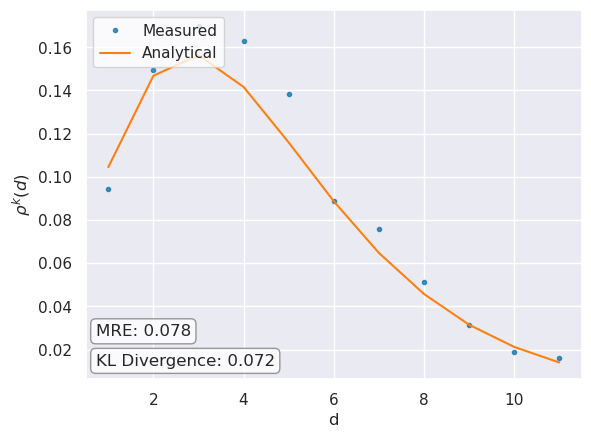

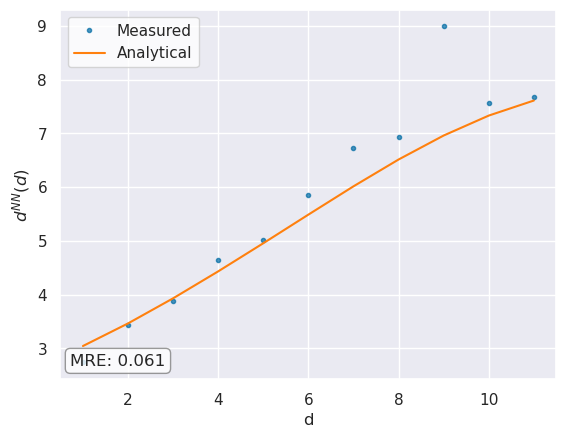

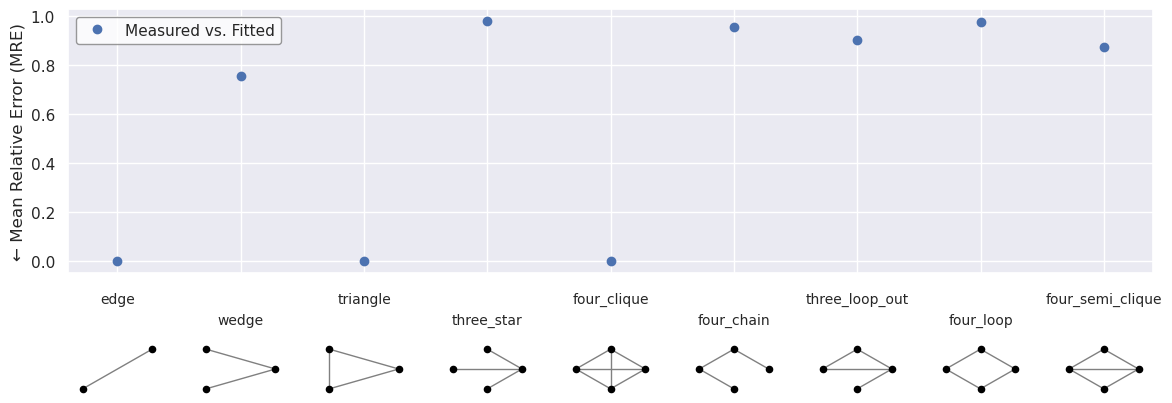

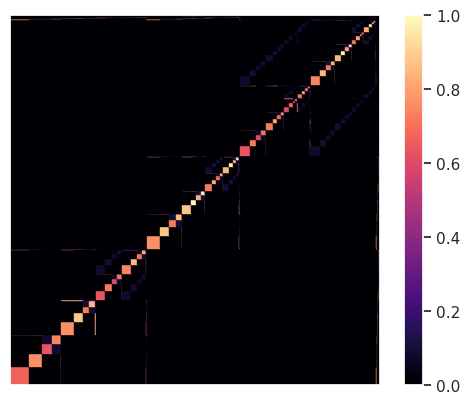

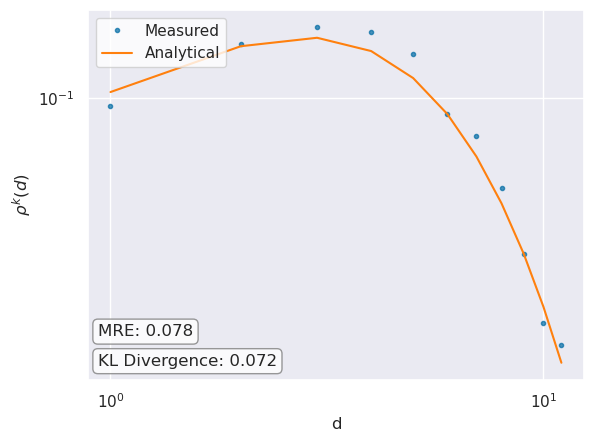

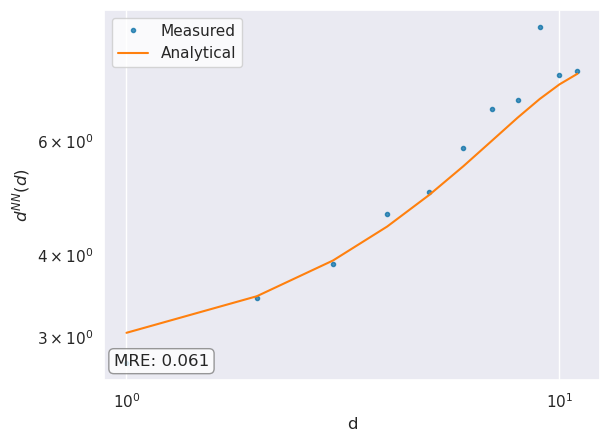

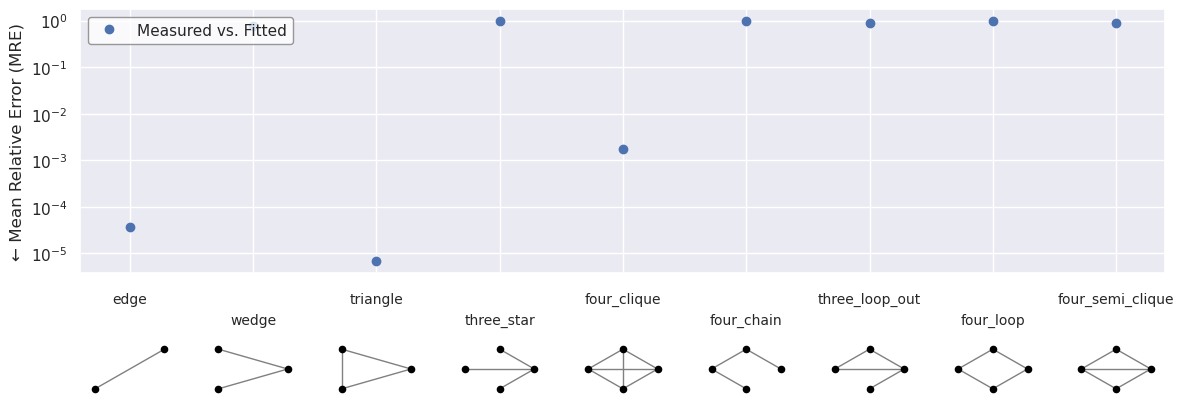

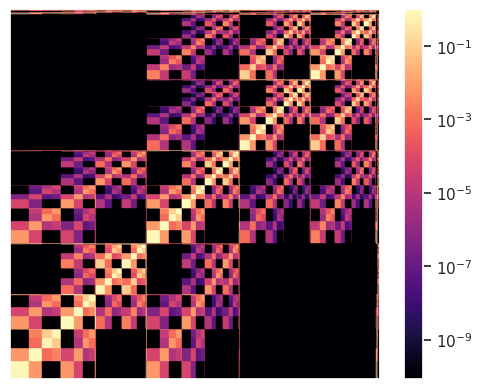

In [16]:
mfnf.plot_P_l_result(
    log_scale = False,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False,
    #filename = "figures/horses_individual_plot.pdf"
)
mfnf.plot_P_l_result(
    log_scale = True,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False,
    #filename = "figures/horses_individual_log_plot.pdf"
)

# Bootstrapping Stability

In [20]:
mfnf.bootstrap_P_l_stability(
    P_init = 'm x m',
    l_init = 'dirichlet',
    verbose = True,
    resample_size = mfnf.population_size,
    ci = 0.95,
    medoid = 'lowest'
)

Gathering statistics (30 runs)...


100%|██████████| 30/30 [56:41<00:00, 113.38s/it]

Bootstrapping: Resampling 100 times...


Bootstrapping finished in 0:00:00.256075
Energy = 6.67 (6.67, 6.89)
l = [0.36 (0.24, 0.38), 0.31 (0.21, 0.34), 0.17 (0.16, 0.30), 0.16 (0.00, 0.19), 0.01 (0.00, 0.14), 0.00 (0.00, 0.01)]
P = [
[0.93 (0.57, 0.98), 0.00 (0.00, 0.02), 0.00 (0.00, 0.03), 0.00 (0.00, 1.00), 1.00 (0.00, 1.00), 0.57 (0.00, 1.00)],

[0.00 (0.00, 0.02), 0.82 (0.51, 1.00), 0.00 (0.00, 0.07), 0.00 (0.00, 1.00), 1.00 (0.00, 1.00), 0.84 (0.00, 1.00)],

[0.00 (0.00, 0.03), 0.00 (0.00, 0.07), 1.00 (0.74, 1.00), 0.14 (0.00, 1.00), 0.35 (0.00, 1.00), 0.89 (0.00, 1.00)],

[0.00 (0.00, 1.00), 0.00 (0.00, 1.00), 0.14 (0.00, 1.00), 0.92 (0.22, 1.00), 0.00 (0.00, 1.00), 0.33 (0.00, 1.00)],

[1.00 (0.00, 1.00), 1.00 (0.00, 1.00), 0.35 (0.00, 1.00), 0.00 (0.00, 1.00), 0.86 (0.00, 1.00), 0.73 (0.00, 1.00)],

[0.57 (0.00, 1.00), 0.84 (0.00, 1.00), 0.89 (0.00, 1.00), 0.33 (0.00, 1.00), 0.73 (0.00, 1.00), 0.73 (0.00, 1.00)]
]


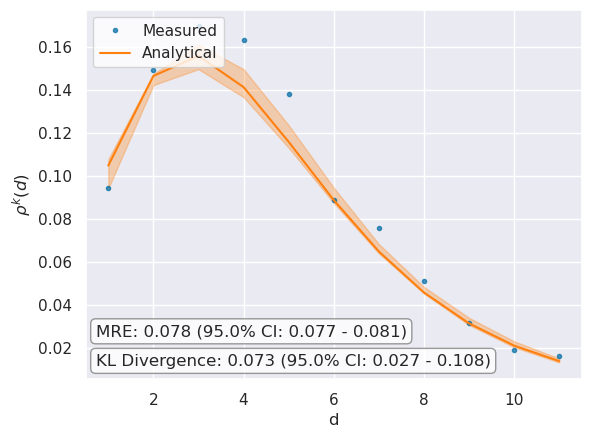

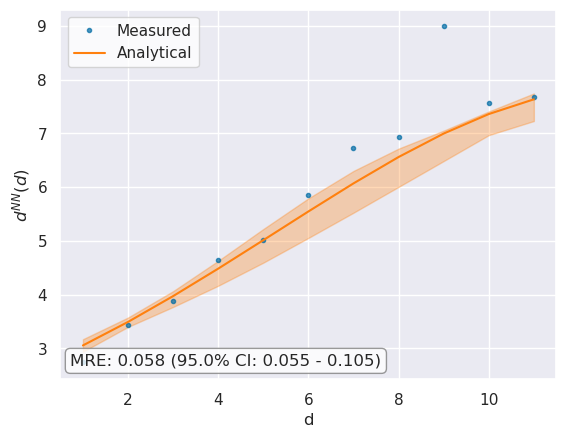

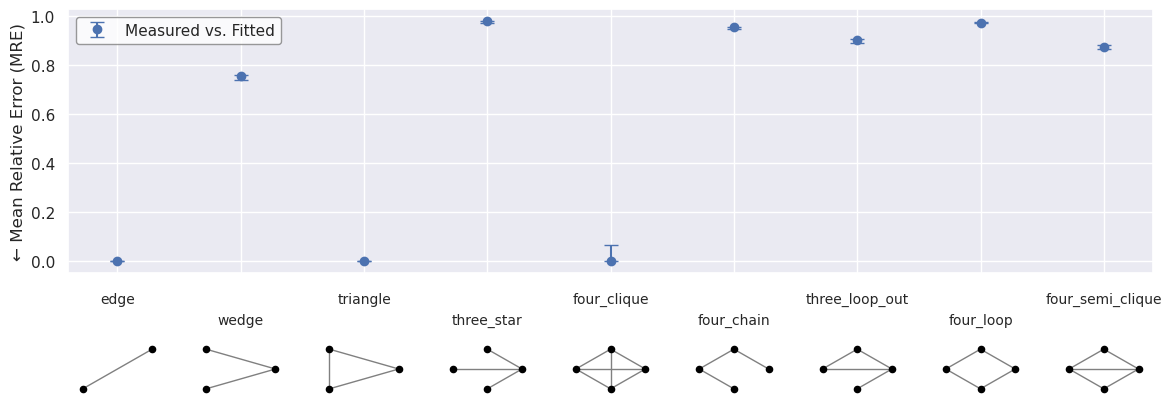

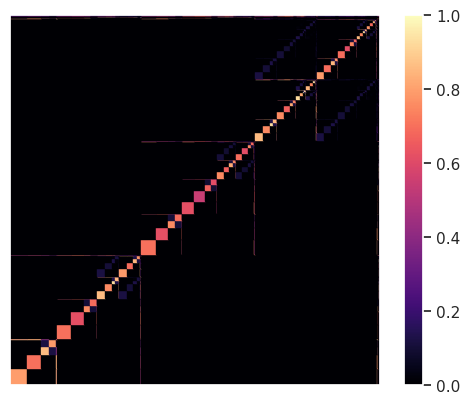

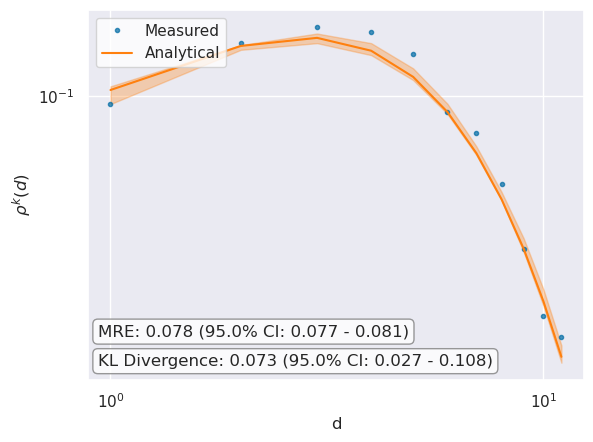

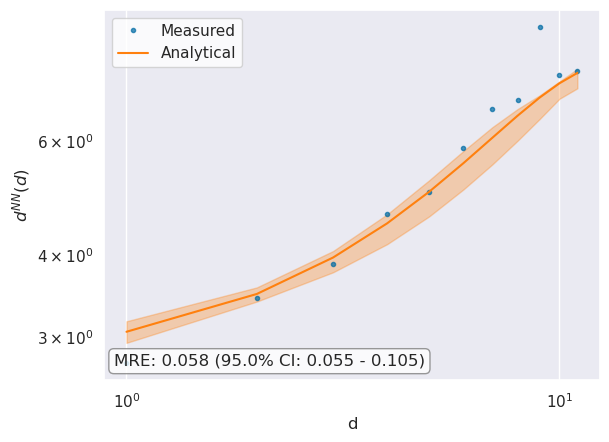

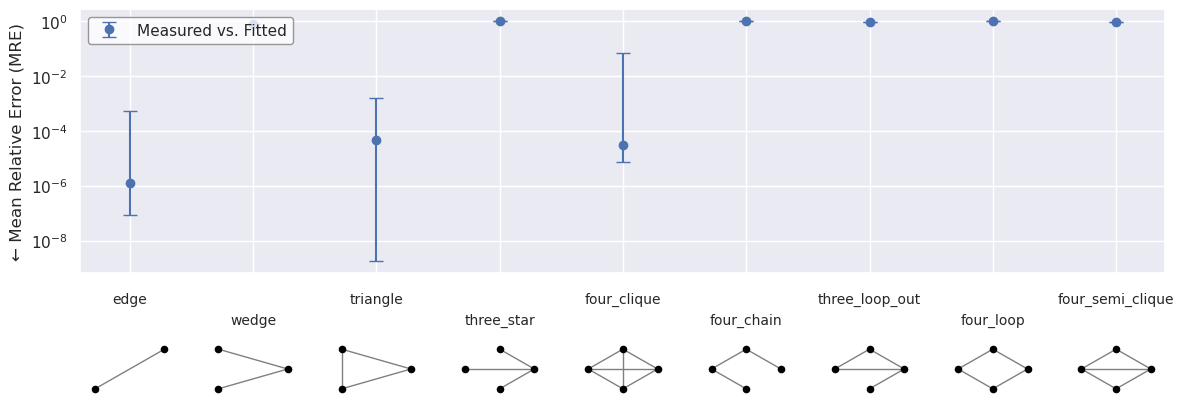

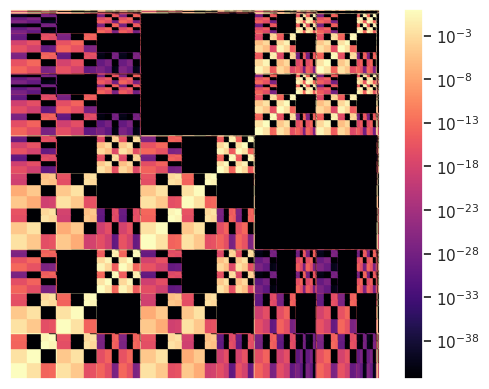

In [21]:
mfnf.plot_P_l_result(
    log_scale = False,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False,
    filename = "figures/horses_individual_plot.pdf"
)
mfnf.plot_P_l_result(
    log_scale = True,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False,
    filename = "figures/horses_individual_log_plot.pdf"
)

# Generate Variants

Initializing...
0.0012845993041992188
Calculating betweenness...
Done.
Calculating node positions...
Done.


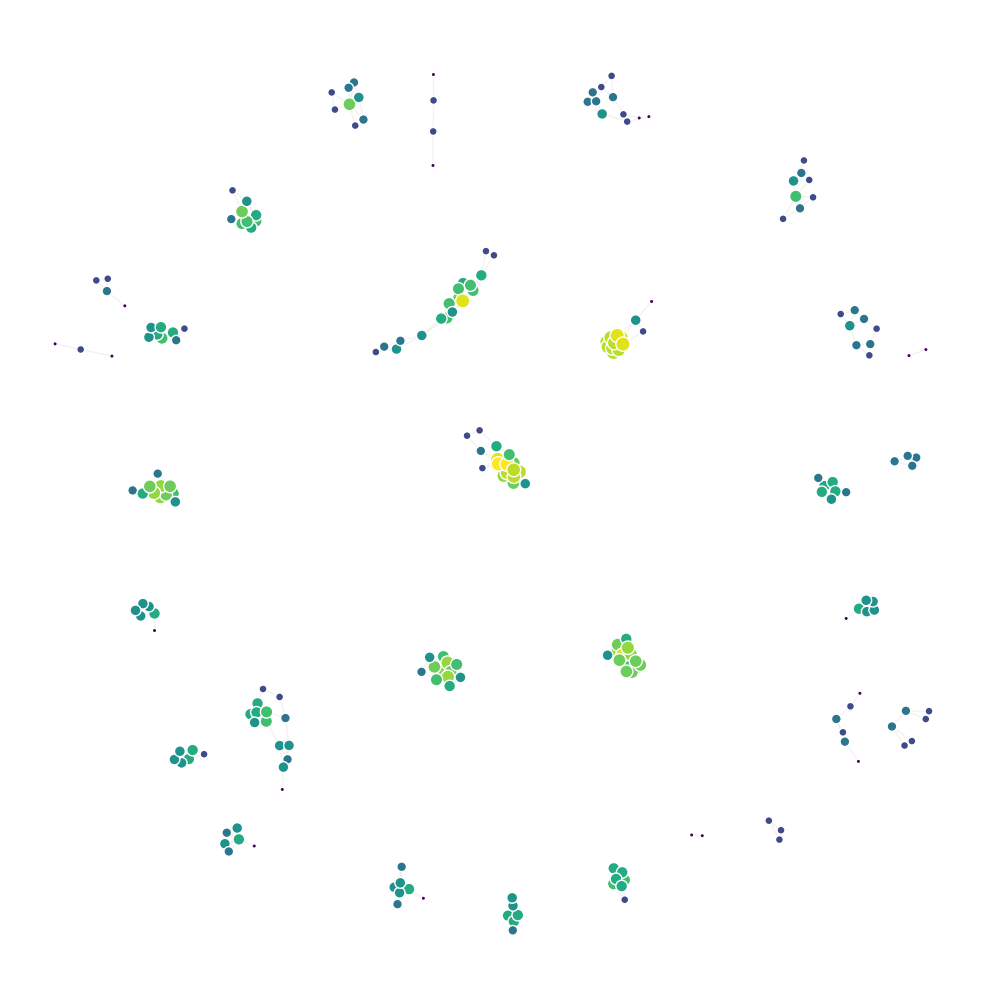

Preparing node pairs...
Commencing edge generation...


100%|██████████| 32/32 [00:00<00:00, 639.41it/s]

Refining network structure...


Calculating betweenness...
Done.
Calculating node positions...
Done.


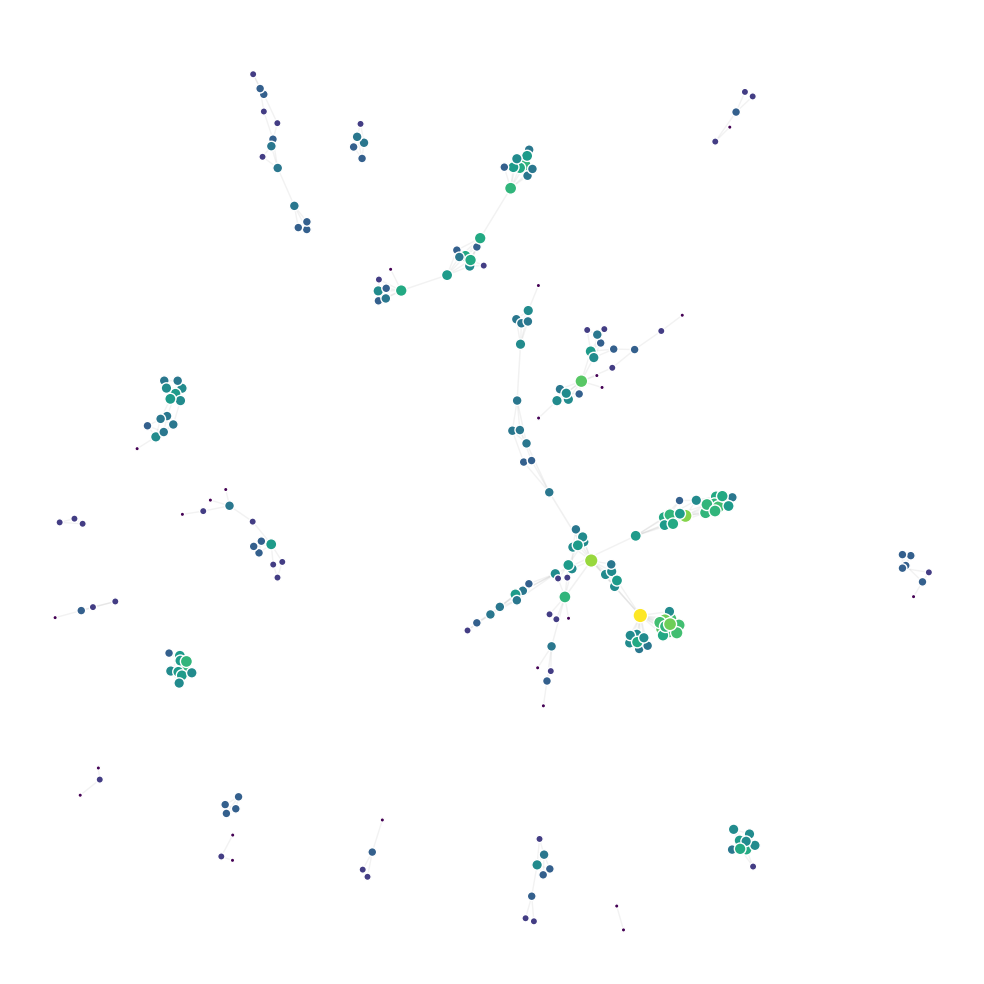

Preparing node pairs...
Commencing edge generation...


100%|██████████| 32/32 [00:00<00:00, 603.65it/s]

Refining network structure...


Calculating betweenness...
Done.
Calculating node positions...
Done.


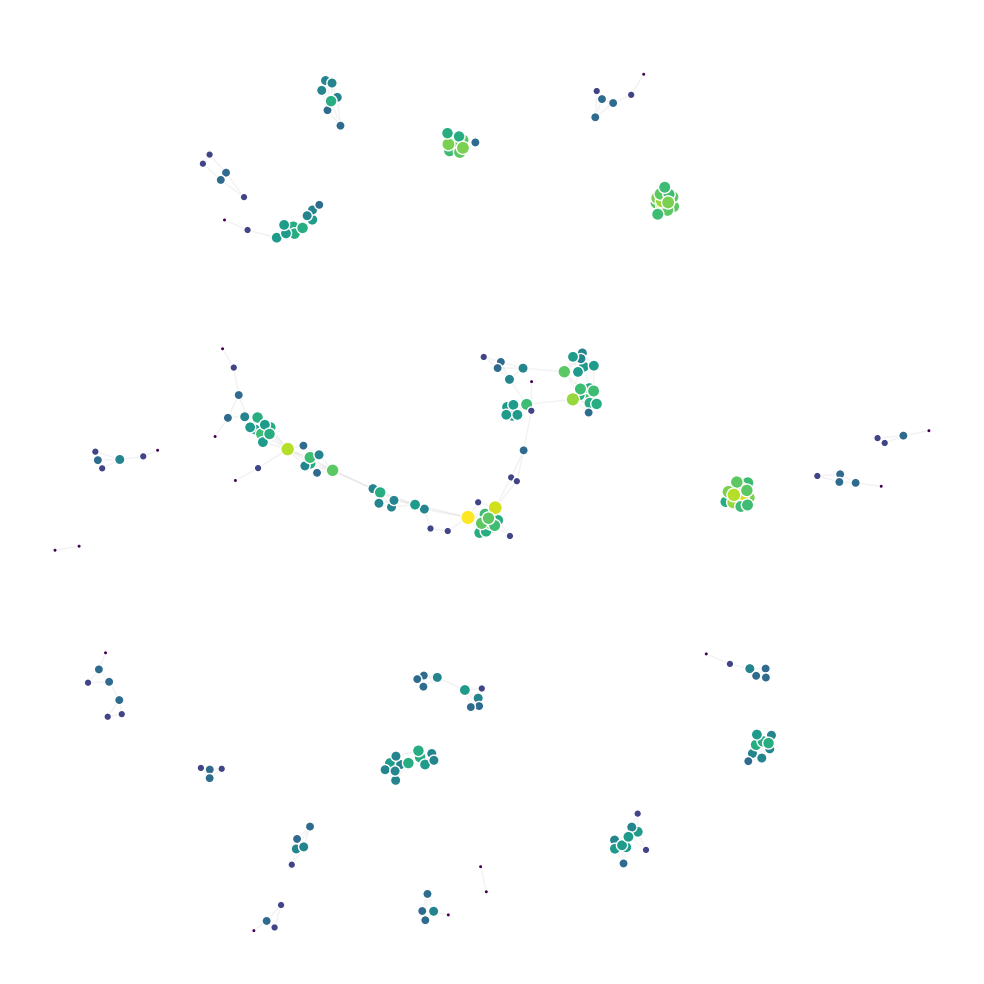

Preparing node pairs...
Commencing edge generation...


100%|██████████| 32/32 [00:00<00:00, 597.17it/s]

Refining network structure...


Calculating betweenness...
Done.
Calculating node positions...
Done.


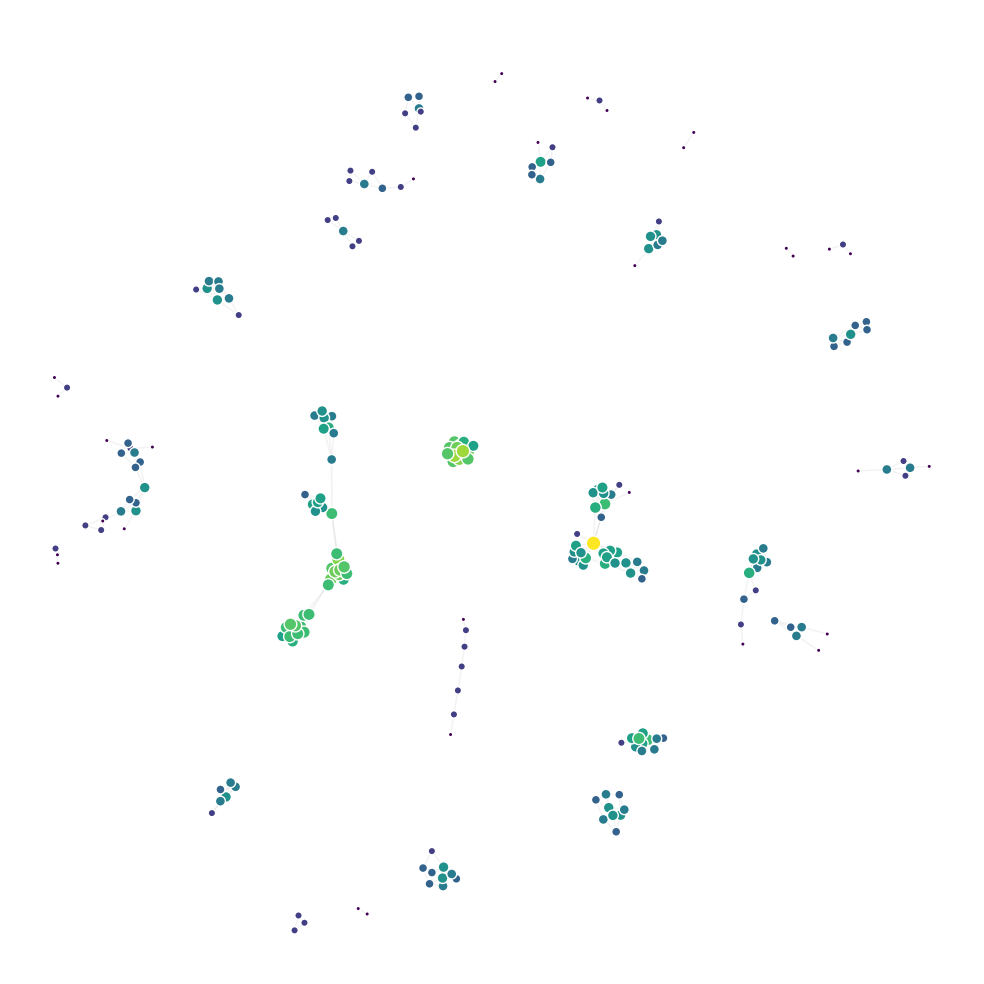

In [22]:
mfnf.generate_variants(
    plot_options = {
        'layout_func': nx.spring_layout,
        'figsize': (10,10),
        'filename':  "figures/horses_individual_variants.pdf"
    },
    filename = "variant_networks/horses_individual_variants.graphml"
)